## Safola Bhattarai (Week3)

### Collecting Documents

In [19]:
import os
import re
import math

DOC_DIR = "documents"
documents = {}
for fname in sorted(os.listdir(DOC_DIR)):
    if fname.endswith(".txt"):
        doc_id = fname.replace(".txt", "")
        with open(os.path.join(DOC_DIR, fname), encoding="utf-8") as f:
            documents[doc_id] = f.read().strip()

for doc_id, text in documents.items():
    print(doc_id, ":", text[:70], "...")
print("Total documents:", len(documents))

D1 : Artificial intelligence (AI) and machine learning (ML) are innovative  ...
D2 : Machine Learning (ML) is a subfield of Artificial Intelligence (AI) th ...
D3 : One of the primary benefits of sports is the improvement of physical f ...
D4 : WHO defines physical activity as any bodily movement produced by skele ...
D5 : Natural Language Processing (NLP) is the study and development of syst ...
D6 : Speech recognition, or speech-to-text, is the ability of a machine or  ...
Total documents: 6


In [20]:
for fname in sorted(os.listdir(DOC_DIR)):
    path = os.path.join(DOC_DIR, fname)
    size = os.path.getsize(path)
    print(fname, "->", size, "bytes")

D1.txt -> 450 bytes
D2.txt -> 364 bytes
D3.txt -> 344 bytes
D4.txt -> 525 bytes
D5.txt -> 615 bytes
D6.txt -> 745 bytes


### Text preprocessing and Tokenization


In [21]:
STOPWORDS = set("""a an the and or but if while is are was were be been
being to of in on for with as by at from this that these those it its
their his her he she they them we you your our i not no can could will
would should than then so such also more most much many any all each
other into over under up down out about after before between during
without within""".split())

def tokenize(text):
    text = text.lower()
    tokens = re.findall(r"\b[a-z]+\b", text)
    return [t for t in tokens if t not in STOPWORDS]

tokenized_docs = {d: tokenize(t) for d, t in documents.items()}
for doc_id, tokens in tokenized_docs.items():
    print(doc_id, ":", tokens[:10], "...")

D1 : ['artificial', 'intelligence', 'ai', 'machine', 'learning', 'ml', 'innovative', 'fields', 'focused', 'enabling'] ...
D2 : ['machine', 'learning', 'ml', 'subfield', 'artificial', 'intelligence', 'ai', 'focuses', 'building', 'algorithms'] ...
D3 : ['one', 'primary', 'benefits', 'sports', 'improvement', 'physical', 'fitness', 'regular', 'physical', 'activity'] ...
D4 : ['who', 'defines', 'physical', 'activity', 'bodily', 'movement', 'produced', 'skeletal', 'muscles', 'requires'] ...
D5 : ['natural', 'language', 'processing', 'nlp', 'study', 'development', 'systems', 'designed', 'train', 'computers'] ...
D6 : ['speech', 'recognition', 'speech', 'text', 'ability', 'machine', 'program', 'identify', 'words', 'spoken'] ...


In [22]:
vocabulary = sorted(set(term for tokens in tokenized_docs.values() for term in tokens))
print("Vocabulary size:", len(vocabulary))
print(vocabulary[:20], "...")

Vocabulary size: 217
['ability', 'accents', 'achieve', 'active', 'activities', 'activity', 'addresses', 'ai', 'aids', 'algorithms', 'allow', 'aloud', 'analyses', 'analyze', 'analyzing', 'array', 'artificial', 'audio', 'based', 'benefits'] ...


### Term Frequency 

In [23]:
def compute_tf(tokens):
    tf = {}
    total_terms = len(tokens)
    for term in tokens:
        tf[term] = tf.get(term, 0) + 1
    for term in tf:
        tf[term] = tf[term] / total_terms
    return tf

tf_scores = {d: compute_tf(t) for d, t in tokenized_docs.items()}

top5 = sorted(tf_scores["D1"].items(), key=lambda x: -x[1])[:5]
print("Top 5 terms in D1 by TF:")
for term, score in top5:
    print(f"  {term}: {score:.4f}")

Top 5 terms in D1 by TF:
  learning: 0.0625
  intelligence: 0.0417
  ai: 0.0417
  machine: 0.0417
  perform: 0.0417


### Inverse Document Frequency

In [25]:
def compute_idf(vocabulary, tokenized_docs):
    N = len(tokenized_docs)
    idf = {}
    for term in vocabulary:
        df = sum(1 for t in tokenized_docs.values() if term in t)
        idf[term] = math.log(N / df) + 1
    return idf

idf_scores = compute_idf(vocabulary, tokenized_docs)

sample_terms = ["ai", "energy", "team"]
for term in sample_terms:
    if term in idf_scores:
        print(f"  {term}: idf = {idf_scores[term]:.4f}")

  ai: idf = 2.0986
  energy: idf = 2.7918


### Building TF IDF Vectors 

In [26]:
def compute_tfidf(tf, idf, vocabulary):
    return [tf.get(term, 0.0) * idf[term] for term in vocabulary]

tfidf_vectors = {d: compute_tfidf(tf_scores[d], idf_scores, vocabulary) for d in documents}

print("TF-IDF vector length:", len(tfidf_vectors["D1"]))
nonzero = sum(1 for v in tfidf_vectors["D1"] if v > 0)
print("Non-zero weights in D1 vector:", nonzero)

TF-IDF vector length: 217
Non-zero weights in D1 vector: 40


### Cosine Similarity Matrix

In [27]:
def cosine_similarity(vec_a, vec_b):
    dot = sum(a * b for a, b in zip(vec_a, vec_b))
    norm_a = math.sqrt(sum(a * a for a in vec_a))
    norm_b = math.sqrt(sum(b * b for b in vec_b))
    if norm_a == 0 or norm_b == 0:
        return 0.0
    return dot / (norm_a * norm_b)

doc_ids = list(documents.keys())
similarity_matrix = [[cosine_similarity(tfidf_vectors[i], tfidf_vectors[j]) for j in doc_ids] for i in doc_ids]

print("      " + "  ".join(f"{d:>5}" for d in doc_ids))
for i, row in zip(doc_ids, similarity_matrix):
    print(f"{i:>5} " + "  ".join(f"{v:5.2f}" for v in row))

         D1     D2     D3     D4     D5     D6
   D1  1.00   0.32   0.00   0.00   0.10   0.03
   D2  0.32   1.00   0.00   0.01   0.08   0.02
   D3  0.00   0.00   1.00   0.17   0.00   0.00
   D4  0.00   0.01   0.17   1.00   0.00   0.00
   D5  0.10   0.08   0.00   0.00   1.00   0.07
   D6  0.03   0.02   0.00   0.00   0.07   1.00


### Ranking Document Similarity 

In [28]:
pairs = []
for a in range(len(doc_ids)):
    for b in range(a + 1, len(doc_ids)):
        pairs.append((doc_ids[a], doc_ids[b], similarity_matrix[a][b]))
pairs.sort(key=lambda x: -x[2])

print("Ranked document pairs (most to least similar):")
for a, b, score in pairs:
    print(f"  {a} - {b}: {score:.4f}")

Ranked document pairs (most to least similar):
  D1 - D2: 0.3228
  D3 - D4: 0.1667
  D1 - D5: 0.0958
  D2 - D5: 0.0774
  D5 - D6: 0.0692
  D1 - D6: 0.0336
  D2 - D6: 0.0233
  D2 - D4: 0.0128
  D1 - D3: 0.0000
  D1 - D4: 0.0000
  D2 - D3: 0.0000
  D3 - D5: 0.0000
  D3 - D6: 0.0000
  D4 - D5: 0.0000
  D4 - D6: 0.0000


### Visualizing the Similarity Matrix 

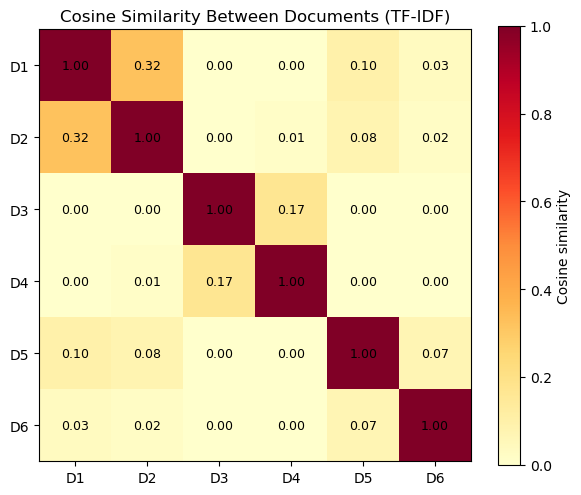

In [29]:
import matplotlib.pyplot as plt
import numpy as np

sim_array = np.array(similarity_matrix)

fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(sim_array, cmap="YlOrRd", vmin=0, vmax=1)
ax.set_xticks(range(len(doc_ids))); ax.set_xticklabels(doc_ids)
ax.set_yticks(range(len(doc_ids))); ax.set_yticklabels(doc_ids)
ax.set_title("Cosine Similarity Between Documents (TF-IDF)")

for i in range(len(doc_ids)):
    for j in range(len(doc_ids)):
        ax.text(j, i, f"{sim_array[i,j]:.2f}", ha="center", va="center", fontsize=9)

fig.colorbar(im, ax=ax, label="Cosine similarity")
plt.tight_layout()
plt.savefig("similarity_heatmap.png", dpi=150)
plt.show()

### Most Similar Document Finder

In [30]:
def most_similar(doc_id):
    scores = [(other, similarity_matrix[doc_ids.index(doc_id)][doc_ids.index(other)])
              for other in doc_ids if other != doc_id]
    scores.sort(key=lambda x: -x[1])
    return scores[0]

for d in doc_ids:
    match, score = most_similar(d)
    print(f"{d} is most similar to {match} (score: {score:.4f})")

D1 is most similar to D2 (score: 0.3228)
D2 is most similar to D1 (score: 0.3228)
D3 is most similar to D4 (score: 0.1667)
D4 is most similar to D3 (score: 0.1667)
D5 is most similar to D1 (score: 0.0958)
D6 is most similar to D5 (score: 0.0692)
